# Valve limit-switch alerts: walkthrough

Stage by stage on the simulated SOE log: load the records, rebuild every valve stroke, learn each valve's normal, raise operator alerts, and score them against the injected faults and against plain DCS alarms.

*All data is simulated. No plant or DCS data is used.*

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 140)

## 1. Load the data

In [2]:
from src.data.load_data import load_data, load_truth
reg, events = load_data()
print(len(reg), 'valves |', len(events), 'SOE records')
events[events.tag == 'XV-1101'].iloc[2:10][['ts', 'point', 'value']]

45 valves | 134089 SOE records


,ts,point,value
171,2025-01-01 04:32:39.116,XV-1101.CMD,1
172,2025-01-01 04:32:39.476,XV-1101.ZSC,0
173,2025-01-01 04:32:41.922,XV-1101.ZSO,1
183,2025-01-01 04:58:36.524,XV-1101.CMD,0
184,2025-01-01 04:58:36.901,XV-1101.ZSO,0
185,2025-01-01 04:58:39.224,XV-1101.ZSC,1
228,2025-01-01 09:21:03.576,XV-1101.CMD,1
229,2025-01-01 09:21:04.029,XV-1101.ZSC,0


## 2. Rebuild strokes (features)
**Breakaway** = command to start switch dropping; **travel** = start switch dropping to end switch making.

In [3]:
from src.features.strokes import parse_strokes
strokes, uncmd = parse_strokes(events, reg)
print(strokes.status.value_counts().to_dict(), '|', len(uncmd), 'uncommanded switch changes')
strokes.head()

{'complete': 40587, 'not_confirmed': 1350, 'complete_start_switch_not_made': 1350, 'no_move': 368} | 6470 uncommanded switch changes


,tag,direction,t_cmd,breakaway_s,travel_s,total_s,status,start_switch_made_before
0,XV-1101,open,2025-01-01 04:32:39.116,0.360,2.446,2.806,complete,True
1,XV-1101,close,2025-01-01 04:58:36.524,0.377,2.323,2.700,complete,True
2,XV-1101,open,2025-01-01 09:21:03.576,0.453,2.432,2.885,complete,True
3,XV-1101,close,2025-01-01 10:48:05.859,0.376,2.397,2.773,complete,True
4,XV-1101,open,2025-01-01 14:32:52.077,0.345,2.451,2.796,complete,True


## 3. Learn each valve's normal (the 'model')

In [4]:
from src.models.baseline import baselines
base = baselines(strokes)
base.head()

,tag,direction,n_learn,base_total_s,mad_total_s,base_break_s,mad_break_s,learn_until
0,SDV-2101,close,10,15.0060,0.300120,0.7055,0.042995,2025-02-27 03:43:15.103
1,SDV-2101,open,10,17.8215,0.850271,0.7440,0.067458,2025-02-23 14:54:22.604
2,SDV-2102,close,11,7.0970,0.278729,0.7830,0.103782,2025-02-28 08:37:58.552
3,SDV-2102,open,12,8.5625,0.280953,0.7410,0.091180,2025-02-28 16:59:41.707
4,SDV-2103,close,10,10.9900,0.371391,0.3680,0.045961,2025-02-28 21:49:19.602


## 4. Operator alerts vs plain DCS alarms

In [5]:
from src.alerts.rules import dcs_alarms, raw_alerts, shelve
alerts = shelve(raw_alerts(strokes, uncmd, reg, base))
dcs = dcs_alarms(strokes, uncmd, reg)
print(len(alerts), 'operator alerts vs', len(dcs), 'plain DCS alarms')
alerts.groupby('rule').size()

2044 operator alerts vs 10156 plain DCS alarms


rule
chattering        512
fail_to_move      196
limit_exceeded    342
not_confirmed     550
slow_trend        142
sticking          201
uncommanded       101
dtype: int64

In [6]:
alerts[alerts.rule.isin(['slow_trend', 'sticking', 'not_confirmed'])].drop_duplicates('rule')[['tag', 'ts', 'priority', 'message']]

,tag,ts,priority,message
2,XV-1102,2025-03-19 01:54:35.349,High,XV-1102 open command: open switch not made within 8 s: valve stuck part-way or open switch fault
261,XV-1113,2025-06-25 03:50:02.138,Low,XV-1113 hesitating on close: breakaway 3.1 s vs normal 0.6 s (2 of last 6 strokes)
490,XV-1127,2025-07-31 10:22:00.730,Low,"XV-1127 open time trending up: 3.6 s vs normal 3.1 s (+19%), projected to reach the 5.3 s limit in about 21 days. Check air supply, actu..."


## 5. Score against the injected faults

In [7]:
from src.models.evaluate import evaluate
det, load = evaluate(alerts, dcs, load_truth(), reg)
det[['tag', 'fault', 'onset', 'cause_named', 'alert_delay_days', 'earlier_than_dcs_days']]

,tag,fault,onset,cause_named,alert_delay_days,earlier_than_dcs_days
0,XV-1102,switch,2025-03-18 19:53:03,True,0.251069,0.000000
1,XV-1104,drift,2025-08-30 18:19:12,True,7.974169,16.461893
2,XV-1105,sticking,2025-08-06 12:07:57,True,0.095616,0.000000
3,XV-1106,switch,2025-06-18 09:23:58,True,0.154200,0.000000
4,XV-1110,drift,2025-07-19 17:29:56,True,17.985146,52.496992
5,XV-1113,sticking,2025-06-24 02:35:32,True,0.056519,0.000000
6,XV-1115,switch,2025-04-03 11:07:16,True,0.492875,0.000000
7,XV-1117,no_move,2025-08-28 14:37:24,True,1.709016,0.000000
8,XV-1127,drift,2025-07-18 14:06:05,True,12.844395,39.782144
9,XV-1128,sticking,2025-08-10 22:49:40,True,2.234388,0.000000


In [8]:
load

{'alerts_total': 2044,
 'alerts_suppressed_repeats': 2317,
 'dcs_alarms_total': 10156,
 'alerts_per_day_mean': 7.1,
 'dcs_alarms_per_day_mean': 35.1,
 'alerts_peak_day': 16,
 'dcs_peak_day': 86,
 'false_alerts_healthy_valves': 0,
 'false_alerts_before_onset': 0,
 'healthy_valves': 25,
 'chatter_valves_dcs_alarms': 6470,
 'chatter_valves_operator_alerts': 613}

## Figures (full pipeline)

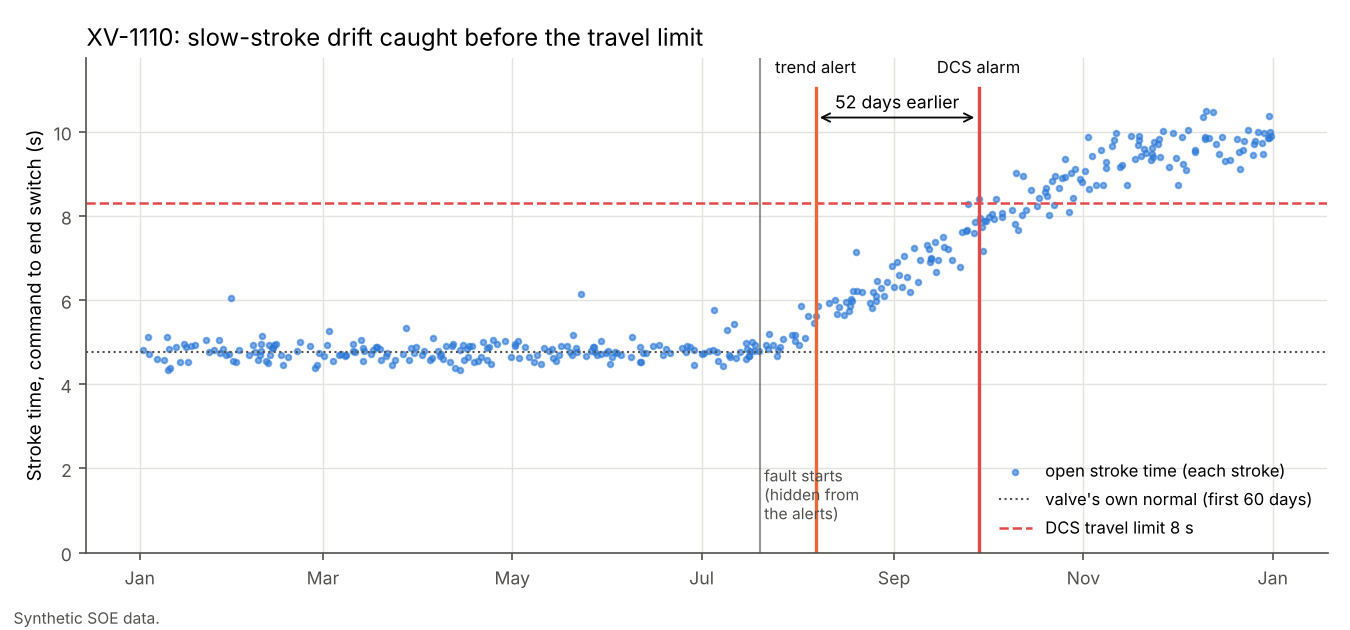

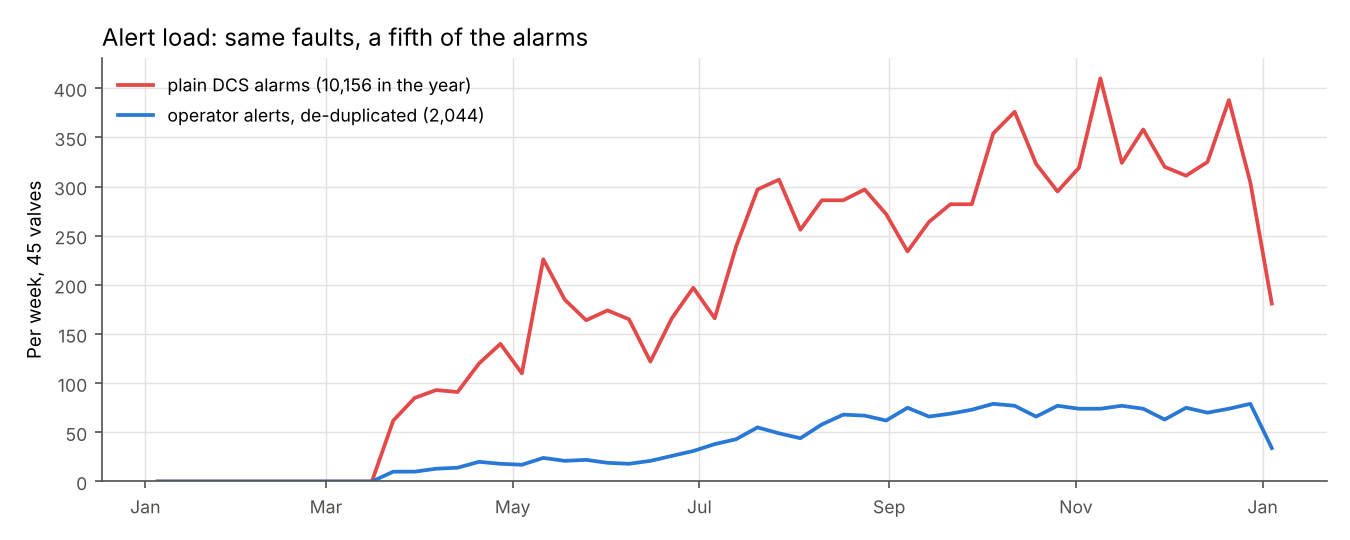

In [9]:
from src import pipeline
from src.utils import plots
strokes, alerts, dcs, det, summary, load, reg, faults, base = pipeline.run()
plots.drift_timeline(strokes, alerts, dcs, det, reg, base)
plots.alert_load(alerts, dcs)
from IPython.display import Image, display
display(Image('reports/figures/drift_timeline.png', width=800))
display(Image('reports/figures/alert_load.png', width=800))

## Serve it
`uvicorn src.api.app:app --reload`, then open http://127.0.0.1:8000/docs. The same call from Python, for the drifting valve XV-1110:

In [10]:
from fastapi.testclient import TestClient
from src.api.app import app
raw = pd.read_csv('data/raw/soe_events.csv.gz')
v = reg.set_index('tag').loc['XV-1110']
body = dict(valve=dict(tag='XV-1110', service=v.service, open_s=v.open_s, close_s=v.close_s, open_limit_s=v.open_limit_s, close_limit_s=v.close_limit_s),
            events=raw[raw.point.str.startswith('XV-1110.')].to_dict('records'))
r = TestClient(app).post('/alerts', json=body).json()
print(r['strokes'], 'strokes', r['stroke_status'])
r['alerts'][:3]

757 strokes {'complete': 757}


[{'tag': 'XV-1110',
  'ts': '2025-08-06 17:08:32.601',
  'rule': 'slow_trend',
  'priority': 'Low',
  'message': 'XV-1110 open time trending up: 5.6 s vs normal 4.8 s (+17%), projected to reach the 8.3 s limit in about 40 days. Check air supply, actuator, packing',
  'repeats_suppressed': 1},
 {'tag': 'XV-1110',
  'ts': '2025-08-11 01:11:52.964',
  'rule': 'slow_trend',
  'priority': 'Low',
  'message': 'XV-1110 open time trending up: 5.9 s vs normal 4.8 s (+24%), projected to reach the 8.3 s limit in about 34 days. Check air supply, actuator, packing',
  'repeats_suppressed': 0},
 {'tag': 'XV-1110',
  'ts': '2025-08-12 20:21:18.121',
  'rule': 'slow_trend',
  'priority': 'Low',
  'message': 'XV-1110 open time trending up: 6.0 s vs normal 4.8 s (+25%), projected to reach the 8.3 s limit in about 51 days. Check air supply, actuator, packing',
  'repeats_suppressed': 1}]